# Leyton Orient: post-match briefing and 2026/27 performance review

*Anthony Adusei-Poku · MSc Data Science, University of East London (2025)*

This notebook builds an analyst-style briefing on Leyton Orient from **free, legally usable data**:

1. **Post-match:** Leyton Orient 2-0 Blackpool (Sat 17 Oct 2026), plus the 0-0 at Bradford a week earlier.
2. **Season so far (2026/27):** results, expected goals (xG) for and against, shot profile, corners, home/away.
3. **Are results sustainable?** Expected points from xG, and what early-season numbers have historically predicted the rest of a League One season (2017/18 to 2025/26).
4. **Three seasons of context:** Orient in 2023/24, 2024/25 (6th) and 2025/26 (20th) against League One's top six.
5. **What would most improve results:** a points model of shots on target for and against.
6. **Match model:** a time-weighted Dixon-Coles model, validated against the betting market, used to project the rest of 2026/27 and preview the next three fixtures.

**Data cut-off:** football-data.co.uk 2026/27 file downloaded 19 Oct 2026, covering matches to 10 Oct 2026; the 12 League One results from 15-17 Oct 2026 and the Orient v Blackpool team stats were transcribed by hand from public match pages (see `manual/README.md`).

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import statsmodels.formula.api as smf
from scipy.stats import poisson
from orient import load_matches, team_view, league_table, TEAM
from model import DixonColes, walk_forward, simulate_season, rps

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
FIG = Path("figures"); RES = Path("results"); FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
ORIENT, OPP, GREY, DARK = "#D7182A", "#1f77b4", "#B8B8B8", "#222222"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12})
KEY = {}   # headline numbers, saved to results/key_numbers.json for the README and briefing
def save(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", facecolor="white"); plt.show()

## 1. Data and coverage

| Source | What it gives | Used for |
|---|---|---|
| [football-data.co.uk](https://www.football-data.co.uk/englandm.php) (free CSVs) | Results, half-time scores, shots, shots on target, corners, fouls, cards and bookmaker odds for every EFL match. **From 2026/27 the files also carry a match xG figure (`HxG`, `AxG`)** | Everything below |
| [Sky Sports match stats](https://www.skysports.com/football/leyton-orient-vs-blackpool/stats/7079498450254119232) | Team stats for Orient 2-0 Blackpool (possession, shots, big chances, passes, duels) | Post-match section (transcribed by hand) |
| [Football Web Pages](https://www.footballwebpages.co.uk/league-one/fixtures-results/october) | League One scores, 15-17 Oct 2026 | Bringing the table up to date (transcribed by hand) |

Event or shot-level data (shot locations, set-piece tags, passes by player) for League One is not freely available, so this project works at **team-match level**.
football-data.co.uk's `notes.txt` does not yet document the provider of the new xG columns, so I treat them as indicative and cross-check them against shots below.

In [2]:
allE2 = load_matches("E2")
fd = allE2[allE2.source == "football-data.co.uk"]
cov = allE2.groupby("season").agg(matches=("FTHG", "size"), first=("Date", "min"), last=("Date", "max"),
                                  with_shots=("HS", lambda s: s.notna().sum()),
                                  with_xG=("HxG", lambda s: s.notna().sum()))
cov["first"] = cov["first"].dt.date; cov["last"] = cov["last"].dt.date
cov

,matches,first,last,with_shots,with_xG
season,,,,,
2017/18,552,2017-08-05,2018-05-05,552,0
2018/19,552,2018-08-04,2019-05-04,552,0
2019/20,400,2019-08-03,2020-03-10,400,0
2020/21,552,2020-09-12,2021-05-09,552,0
2021/22,552,2021-08-07,2022-04-30,552,0
2022/23,552,2022-07-30,2023-05-07,552,0
2023/24,552,2023-08-05,2024-04-27,552,0
2024/25,552,2024-08-09,2025-05-03,552,0
2025/26,552,2025-08-01,2026-05-02,552,0


2019/20 was curtailed by COVID-19 (Bury were also expelled, so 23 teams), which is why it has fewer matches; per-game rates are used throughout.
2026/27 has 102 football-data matches to 10 Oct plus 12 hand-entered results.

In [3]:
cur = allE2[allE2.season == "2026/27"]
table = league_table(cur)
KEY["table_date"] = str(cur.Date.max().date())
KEY["orient_pos"], KEY["orient_pts"], KEY["orient_p"] = [int(table.loc[TEAM, c]) for c in ["Pos", "Pts", "P"]]
KEY["orient_wdl"] = [int(table.loc[TEAM, c]) for c in ["W", "D", "L"]]
KEY["orient_gf_ga"] = [int(table.loc[TEAM, "GF"]), int(table.loc[TEAM, "GA"])]
print(f"League One table after matches to {KEY['table_date']} (computed from results; matches the Sky Sports table of 19 Oct 2026)")
table

League One table after matches to 2026-10-17 (computed from results; matches the Sky Sports table of 19 Oct 2026)


,Pos,P,W,D,L,GF,GA,GD,Pts
team,,,,,,,,,
Bradford,1,10,6,2,2,10,5,5,20
Stockport,2,10,6,1,3,21,11,10,19
Huddersfield,3,10,5,4,1,18,9,9,19
Plymouth,4,11,6,1,4,18,14,4,19
Cambridge,5,10,5,4,1,16,12,4,19
Sheffield Weds,6,9,5,3,1,20,8,12,18
Reading,7,10,4,3,3,22,12,10,15
Oxford,8,8,4,3,1,16,9,7,15
Leyton Orient,9,10,4,2,4,15,11,4,14


**Sanity check on the xG column.** Across 2026/27 matches, team xG should track shots and shots on target, and total xG should be close to total goals.

In [4]:
tv = team_view(allE2)
c27 = tv[(tv.season == "2026/27") & tv.xgf.notna()].copy()
print("team-matches with xG:", len(c27))
print("corr(xG, shots) = %.2f, corr(xG, shots on target) = %.2f" % (c27.xgf.corr(c27.sf), c27.xgf.corr(c27.sotf)))
print("total goals %d vs total xG %.1f (ratio %.2f)" % (c27.gf.sum(), c27.xgf.sum(), c27.gf.sum() / c27.xgf.sum()))
print("league xG per shot: %.3f" % (c27.xgf.sum() / c27.sf.sum()))
KEY["xg_corr_shots"], KEY["xg_corr_sot"] = round(c27.xgf.corr(c27.sf), 2), round(c27.xgf.corr(c27.sotf), 2)
KEY["league_goals_27"], KEY["league_xg_27"] = int(c27.gf.sum()), round(c27.xgf.sum(), 1)

team-matches with xG: 204
corr(xG, shots) = 0.68, corr(xG, shots on target) = 0.64
total goals 294 vs total xG 280.7 (ratio 1.05)
league xG per shot: 0.104


The xG figures behave as expected: they correlate with shots on target and add up to close to the goals actually scored. One cross-check against a second provider: for Bradford 0-0 Orient (10 Oct) football-data.co.uk and Sky Sports agree on shots on target (0 and 1) and corners (11 and 2); Sky counts one more Bradford shot (10 v 9).

## 2. Post-match: Leyton Orient 2-0 Blackpool, Saturday 17 October 2026

Goals: Will Forrester (31', header from Alex Gilbert's cross), Dane Scarlett (76', penalty). Attendance 8,055.
The full team stats come from Sky Sports' match page; football-data.co.uk had not yet added this match when it was downloaded.

In [5]:
ms = pd.read_csv("manual/orient_v_blackpool_2026-10-17_match_stats.csv").set_index("stat")
ms

,Leyton Orient,Blackpool
stat,,
Goals,2.0,0.0
Possession %,37.7,62.3
Shots,14.0,16.0
Shots on target,6.0,4.0
Shots off target,6.0,4.0
Big chances missed,3.0,0.0
Hit woodwork,1.0,0.0
Touches in opposition box,16.0,26.0
Corners,3.0,11.0


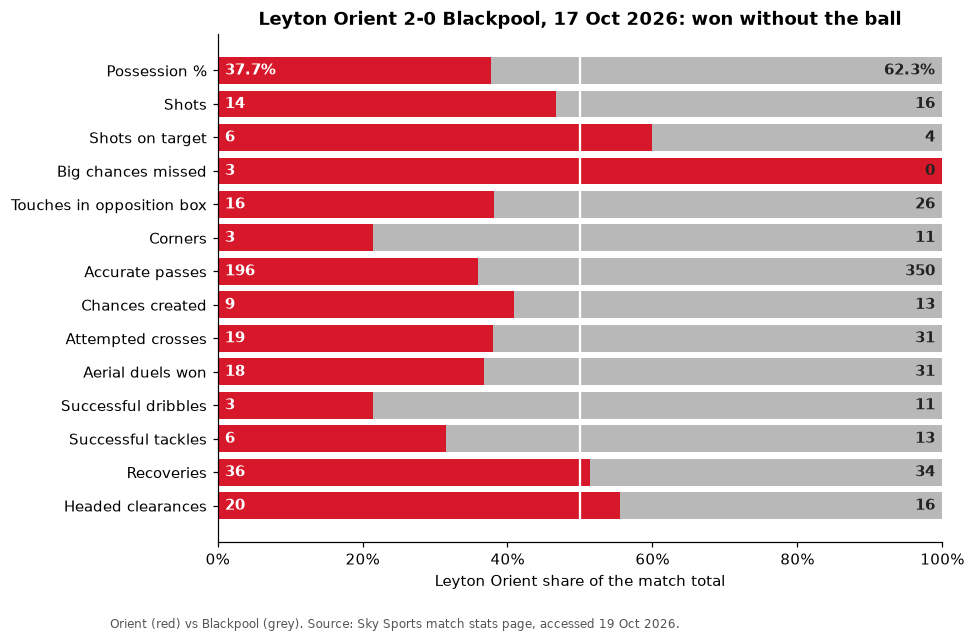

In [6]:
show = ["Possession %", "Shots", "Shots on target", "Big chances missed", "Touches in opposition box",
        "Corners", "Accurate passes", "Chances created", "Attempted crosses", "Aerial duels won",
        "Successful dribbles", "Successful tackles", "Recoveries", "Headed clearances"]
d = ms.loc[show]
share = d["Leyton Orient"] / (d["Leyton Orient"] + d["Blackpool"])
fig, ax = plt.subplots(figsize=(8.5, 6))
y = np.arange(len(show))[::-1]
ax.barh(y, share, color=ORIENT); ax.barh(y, 1 - share, left=share, color=GREY)
for yi, (k, r) in zip(y, d.iterrows()):
    fmt = (lambda v: f"{v:.1f}%") if "%" in k else (lambda v: f"{v:.0f}")
    ax.text(0.01, yi, fmt(r["Leyton Orient"]), va="center", color="white", fontweight="bold")
    ax.text(0.99, yi, fmt(r["Blackpool"]), va="center", ha="right", color=DARK, fontweight="bold")
ax.axvline(0.5, color="white", lw=1.5)
ax.set_yticks(y); ax.set_yticklabels(show); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("Leyton Orient share of the match total")
ax.set_title("Leyton Orient 2-0 Blackpool, 17 Oct 2026: won without the ball")
fig.text(0.01, -0.02, "Orient (red) vs Blackpool (grey). Source: Sky Sports match stats page, accessed 19 Oct 2026.", fontsize=8, color="#555")
save(fig, "01_blackpool_match_stats.png")

**Reading the game.** Blackpool had 62% of the ball, 11 corners to 3, 26 touches in Orient's box to 16 and won 31 aerial duels to 18,
yet Orient had more shots on target (6 v 4) and missed 3 "big chances" to Blackpool's none (Blackpool scored none either, so by that definition they created none), as well as hitting the bar through Olowu's header just before the penalty.
This is the same pattern as the 0-0 at Bradford a week earlier: a low-possession, compact game plan that kept the opposition to few clear chances.

In [7]:
last2 = tv[(tv.team == TEAM) & (tv.Date >= "2026-10-01")][["Date", "venue", "opp", "gf", "ga", "xgf", "xga", "sf", "sa", "sotf", "sota", "cf", "ca"]]
last2

,Date,venue,opp,gf,ga,xgf,xga,sf,sa,sotf,sota,cf,ca
9809,2026-10-03,H,Plymouth,0,2,0.99,1.76,11.0,20.0,4.0,7.0,4.0,6.0
9822,2026-10-10,A,Bradford,0,0,0.34,1.25,9.0,9.0,1.0,0.0,2.0,11.0
9848,2026-10-17,H,Blackpool,2,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


At Bradford, shots were level at 9 each, but Orient held Bradford to **0 shots on target** and 1.25 xG (Orient 0.34).
Bradford's 11 corners to 2 mirror Blackpool's 11 to 3: territory conceded twice in a week.

## 3. Season so far (League One 2026/27)

In [8]:
o27 = tv[(tv.team == TEAM) & (tv.season == "2026/27")].copy()
o27["score"] = o27.gf.astype(int).astype(str) + "-" + o27.ga.astype(int).astype(str)
o27[["Date", "venue", "opp", "score", "result", "xgf", "xga", "sf", "sa", "sotf", "sota", "cf", "ca", "p_win_mkt"]].round(2)

,Date,venue,opp,score,result,xgf,xga,sf,sa,sotf,sota,cf,ca,p_win_mkt
9642,2026-08-15,H,Sheffield Weds,1-2,L,1.42,2.69,10.0,15.0,3.0,5.0,5.0,7.0,0.40
9667,2026-08-22,A,Wigan,2-0,W,0.94,1.36,9.0,16.0,3.0,2.0,3.0,4.0,0.26
9689,2026-08-29,H,Barnsley,1-3,L,0.74,1.98,7.0,16.0,3.0,7.0,4.0,9.0,0.45
9708,2026-09-01,A,Bromley,5-0,W,1.67,0.63,19.0,8.0,11.0,2.0,4.0,2.0,0.32
9734,2026-09-05,A,Luton,1-1,D,0.56,2.21,7.0,23.0,3.0,7.0,2.0,7.0,0.19
9762,2026-09-12,H,Wycombe,2-3,L,1.12,1.16,14.0,14.0,4.0,7.0,6.0,9.0,0.37
9785,2026-09-19,H,Stevenage,1-0,W,0.43,1.54,7.0,16.0,1.0,4.0,3.0,6.0,0.39
9809,2026-10-03,H,Plymouth,0-2,L,0.99,1.76,11.0,20.0,4.0,7.0,4.0,6.0,0.33
9822,2026-10-10,A,Bradford,0-0,D,0.34,1.25,9.0,9.0,1.0,0.0,2.0,11.0,0.18
9848,2026-10-17,H,Blackpool,2-0,W,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


9 matches with xG (to 2026-10-10): goals 13 from 8.21 xG; conceded 11 from 14.58 xGA; shots 10.3 for, 15.2 against per game


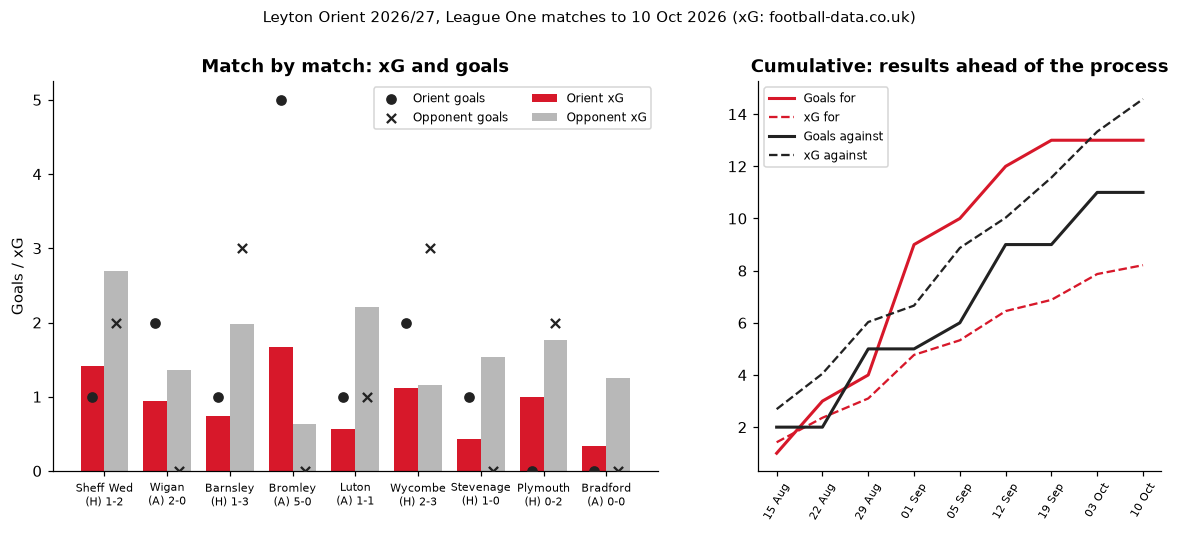

In [9]:
ox = o27.dropna(subset=["xgf"])
KEY["xg_games"] = len(ox); KEY["xg_last_date"] = str(ox.Date.max().date())
KEY["o_gf_xg"] = [int(ox.gf.sum()), round(ox.xgf.sum(), 2)]
KEY["o_ga_xga"] = [int(ox.ga.sum()), round(ox.xga.sum(), 2)]
KEY["o_xgd_pg"] = round((ox.xgf - ox.xga).mean(), 2)
KEY["o_shots_pg"] = [round(ox.sf.mean(), 1), round(ox.sa.mean(), 1)]
KEY["o_bromley"] = [int(ox[ox.opp == "Bromley"].gf.iloc[0]), round(ox[ox.opp == "Bromley"].xgf.iloc[0], 2)]
print(f"{len(ox)} matches with xG (to {KEY['xg_last_date']}): goals {KEY['o_gf_xg'][0]} from {KEY['o_gf_xg'][1]} xG; "
      f"conceded {KEY['o_ga_xga'][0]} from {KEY['o_ga_xga'][1]} xGA; shots {KEY['o_shots_pg'][0]} for, {KEY['o_shots_pg'][1]} against per game")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]; x = np.arange(len(ox)); w = 0.38
ax.bar(x - w/2, ox.xgf, w, color=ORIENT, label="Orient xG"); ax.bar(x + w/2, ox.xga, w, color=GREY, label="Opponent xG")
ax.scatter(x - w/2, ox.gf, color=DARK, marker="o", zorder=3, label="Orient goals")
ax.scatter(x + w/2, ox.ga, color=DARK, marker="x", zorder=3, label="Opponent goals")
short = {"Sheffield Weds": "Sheff Wed", "Milton Keynes Dons": "MK Dons"}
ax.set_xticks(x); ax.set_xticklabels([f"{short.get(r.opp, r.opp)}\n({r.venue}) {r.score}" for r in ox.itertuples()], fontsize=7)
ax.set_ylabel("Goals / xG"); ax.legend(fontsize=8, ncol=2); ax.set_title("Match by match: xG and goals")
ax = axes[1]; dd = ox.Date.dt.strftime("%d %b")
ax.plot(dd, ox.gf.cumsum(), color=ORIENT, lw=2, label="Goals for"); ax.plot(dd, ox.xgf.cumsum(), color=ORIENT, ls="--", label="xG for")
ax.plot(dd, ox.ga.cumsum(), color=DARK, lw=2, label="Goals against"); ax.plot(dd, ox.xga.cumsum(), color=DARK, ls="--", label="xG against")
ax.tick_params(axis="x", rotation=60, labelsize=7.5); ax.legend(fontsize=8); ax.set_title("Cumulative: results ahead of the process")
fig.suptitle(f"Leyton Orient 2026/27, League One matches to {ox.Date.max():%d %b %Y} (xG: football-data.co.uk)", fontsize=10, y=1.02)
save(fig, "02_season_xg_trend.png")

Orient have scored 13 from 8.2 xG and conceded 11 from 14.6 xG. The 5-0 at Bromley accounts for 4 of the 13 goals and just 1.67 xG.
Without that game they scored 8 from 6.5 xG; the defensive over-performance (3.6 goals fewer than xG) runs through the whole season.

In [10]:
lg = c27.groupby("team").agg(P=("pts", "size"), xgf=("xgf", "mean"), xga=("xga", "mean"), sf=("sf", "mean"), sa=("sa", "mean"),
                             sotf=("sotf", "mean"), sota=("sota", "mean"), cf=("cf", "mean"), ca=("ca", "mean"),
                             gf=("gf", "mean"), ga=("ga", "mean"))
lg["xgd"] = lg.xgf - lg.xga; lg["xg_per_shot"] = lg.xgf / lg.sf; lg["xga_per_shot"] = lg.xga / lg.sa
lg = lg.sort_values("xgd", ascending=False); lg["xgd_rank"] = range(1, len(lg) + 1)
for c in ["sf", "sa", "xgf", "xga", "cf", "ca", "xg_per_shot"]:
    KEY[f"rank_{c}"] = int(lg[c].rank(ascending=c in ["sa", "xga", "ca"]).loc[TEAM]) if c in ["sa", "xga", "ca"] else int(lg[c].rank(ascending=False).loc[TEAM])
KEY["o_xgd_rank"] = int(lg.loc[TEAM, "xgd_rank"])
KEY["o_corners_pg"] = [round(lg.loc[TEAM, "cf"], 2), round(lg.loc[TEAM, "ca"], 2)]
KEY["o_xg_per_shot"] = [round(lg.loc[TEAM, "xg_per_shot"], 3), round(lg.loc[TEAM, "xga_per_shot"], 3)]
KEY["lg_xg_per_shot"] = round(c27.xgf.sum() / c27.sf.sum(), 3)
lg.round(2)

,P,xgf,xga,sf,sa,sotf,sota,cf,ca,gf,ga,xgd,xg_per_shot,xga_per_shot,xgd_rank
team,,,,,,,,,,,,,,,
Huddersfield,9,2.07,0.93,15.11,9.22,6.22,2.67,6.67,3.67,1.78,1.00,1.14,0.14,0.10,1
Reading,9,2.05,0.97,16.56,11.00,5.33,3.44,5.67,3.78,2.44,1.22,1.08,0.12,0.09,2
Stockport,9,1.81,1.23,16.33,10.11,5.11,4.22,7.33,3.78,2.22,1.22,0.58,0.11,0.12,3
Luton,8,1.63,1.14,13.38,11.75,4.62,4.12,6.25,3.88,2.00,1.88,0.49,0.12,0.10,4
Sheffield Weds,8,1.93,1.44,14.88,12.75,5.62,3.38,6.88,5.50,1.88,1.00,0.49,0.13,0.11,5
Plymouth,10,1.61,1.32,15.30,12.20,5.40,3.30,5.50,5.40,1.80,1.20,0.29,0.11,0.11,6
Stevenage,8,1.16,0.88,11.12,10.38,4.12,2.38,3.88,5.12,1.50,1.00,0.28,0.10,0.08,7
Bradford,9,1.01,0.76,10.56,10.22,3.22,2.22,6.78,6.11,0.89,0.56,0.25,0.10,0.07,8
Doncaster,8,1.27,1.06,13.75,14.50,3.75,3.75,4.62,6.88,1.12,1.12,0.20,0.09,0.07,9


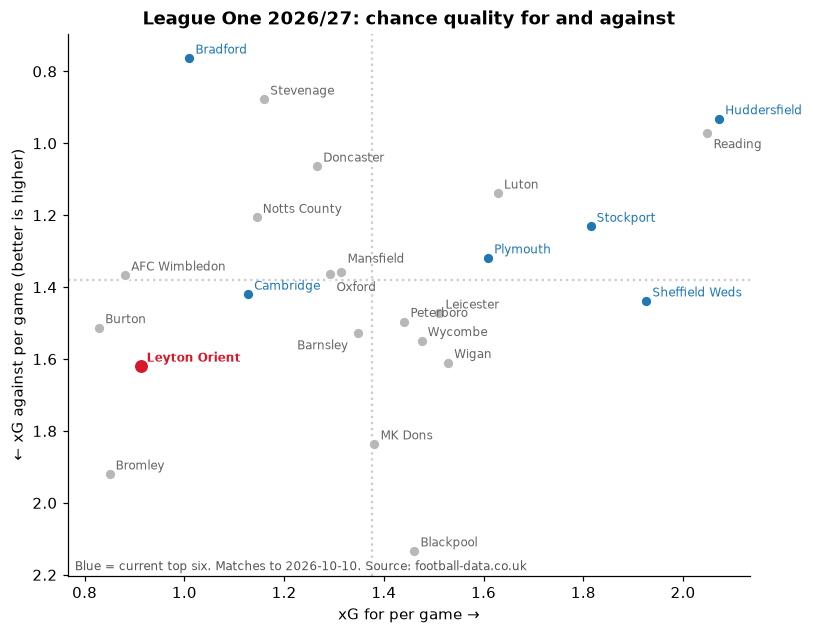

In [11]:
top6 = table.index[:6]
fig, ax = plt.subplots(figsize=(8, 6.4))
for tm, r in lg.iterrows():
    col = ORIENT if tm == TEAM else (OPP if tm in top6 else GREY)
    ax.scatter(r.xgf, r.xga, s=90 if tm == TEAM else 50, color=col, zorder=3, edgecolor="white")
    off = {"Reading": (4, -10), "Mansfield": (4, 6), "Oxford": (4, -11), "Barnsley": (-40, -11)}.get(tm, (4, 3))
    ax.annotate(tm.replace("Milton Keynes Dons", "MK Dons"), (r.xgf, r.xga), xytext=off, textcoords="offset points",
                fontsize=8, color=col if col != GREY else "#666", fontweight="bold" if tm == TEAM else None)
ax.axvline(lg.xgf.mean(), color="#ccc", ls=":"); ax.axhline(lg.xga.mean(), color="#ccc", ls=":")
ax.invert_yaxis(); ax.set_xlabel("xG for per game →"); ax.set_ylabel("← xG against per game (better is higher)")
ax.set_title("League One 2026/27: chance quality for and against")
ax.text(0.01, 0.01, f"Blue = current top six. Matches to {KEY['xg_last_date']}. Source: football-data.co.uk", transform=ax.transAxes, fontsize=8, color="#555")
save(fig, "03_league_xg_scatter.png")

By xG difference per game Orient rank **23rd of 24** (21st for xG created, 21st for xG conceded), while sitting 9th in the table.
The shot profile explains much of it: they take 10.3 shots a game (22nd) and face 15.2 (19th), and their own shots are of lower quality than average (0.088 xG per shot, league 0.104), while the shots they concede are about average (0.106).

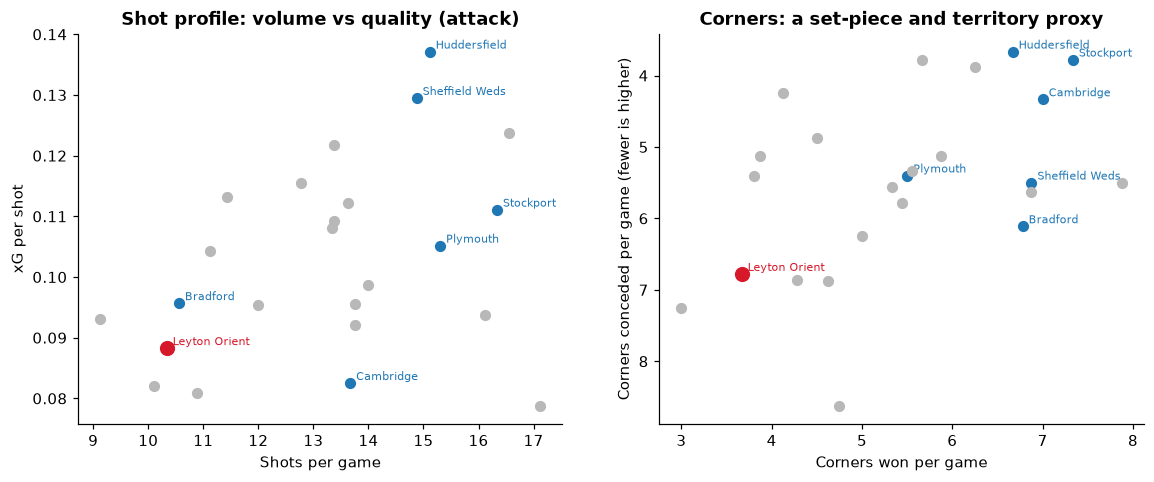

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
ax = axes[0]
for tm, r in lg.iterrows():
    col = ORIENT if tm == TEAM else (OPP if tm in top6 else GREY)
    ax.scatter(r.sf, r.xg_per_shot, color=col, s=80 if tm == TEAM else 40, zorder=3)
    if tm == TEAM or tm in top6: ax.annotate(tm, (r.sf, r.xg_per_shot), xytext=(4, 2), textcoords="offset points", fontsize=7.5, color=col)
ax.set_xlabel("Shots per game"); ax.set_ylabel("xG per shot"); ax.set_title("Shot profile: volume vs quality (attack)")
ax = axes[1]
for tm, r in lg.iterrows():
    col = ORIENT if tm == TEAM else (OPP if tm in top6 else GREY)
    ax.scatter(r.cf, r.ca, color=col, s=80 if tm == TEAM else 40, zorder=3)
    if tm == TEAM or tm in top6: ax.annotate(tm, (r.cf, r.ca), xytext=(4, 2), textcoords="offset points", fontsize=7.5, color=col)
ax.invert_yaxis(); ax.set_xlabel("Corners won per game"); ax.set_ylabel("Corners conceded per game (fewer is higher)")
ax.set_title("Corners: a set-piece and territory proxy")
save(fig, "04_shot_profile_corners.png")

**Set pieces.** The free data has corner counts but not which goals came from set pieces, so this is a volume view only.
Orient win 3.7 corners a game (23rd of 24) and concede 6.8 (20th). In the last two matches Bradford and Blackpool won 11 each.
Defending set pieces is therefore a high-exposure area, and with only 3.7 attacking corners a game, Orient get fewer set-piece chances of their own than almost anyone.

In [13]:
o_ha = tv[(tv.team == TEAM) & (tv.season == "2026/27")].groupby("venue").agg(P=("pts", "size"), pts=("pts", "sum"), ppg=("pts", "mean"),
                                                                            gf=("gf", "sum"), ga=("ga", "sum"))
KEY["o_home"] = o_ha.loc["H", ["P", "pts", "gf", "ga"]].astype(int).tolist(); KEY["o_away"] = o_ha.loc["A", ["P", "pts", "gf", "ga"]].astype(int).tolist()
o_ha

,P,pts,ppg,gf,ga
venue,,,,,
A,4,8,2.0,8,1
H,6,6,1.0,7,10


## 4. Are the results sustainable?

**Expected points.** For each match I turn the two teams' xG into win/draw/loss probabilities (independent Poisson goals) and sum the expected points.

In [14]:
G = np.arange(11)
def xpts(a, b):
    M = np.outer(poisson.pmf(G, a), poisson.pmf(G, b)); return 3 * np.tril(M, -1).sum() + np.trace(M)
c27["xpts"] = [xpts(a, b) for a, b in zip(c27.xgf, c27.xga)]
c27["xpts_mkt"] = 3 * c27.p_win_mkt + c27.p_draw_mkt
xp = c27.groupby("team").agg(P=("pts", "size"), pts=("pts", "sum"), xpts=("xpts", "sum"), mkt=("xpts_mkt", "sum")).sort_values("xpts", ascending=False)
xp["pts_minus_xpts"] = xp.pts - xp.xpts; xp["xpts_rank"] = range(1, len(xp) + 1)
KEY["o_pts_xpts"] = [int(xp.loc[TEAM, "pts"]), round(xp.loc[TEAM, "xpts"], 1), round(xp.loc[TEAM, "mkt"], 1)]
KEY["o_xpts_rank"] = int(xp.loc[TEAM, "xpts_rank"]); KEY["o_luck_rank"] = int(xp.pts_minus_xpts.rank(ascending=False).loc[TEAM])
xp.round(2)

,P,pts,xpts,mkt,pts_minus_xpts,xpts_rank
team,,,,,,
Huddersfield,9,16,18.09,15.83,-2.09,1
Reading,9,15,17.47,14.01,-2.47,2
Stockport,9,16,15.65,16.18,0.35,3
Plymouth,10,19,15.41,15.72,3.59,4
Luton,8,11,13.56,13.12,-2.56,5
Bradford,9,17,13.50,13.88,3.50,6
Sheffield Weds,8,15,12.67,11.00,2.33,7
Peterboro,9,8,12.33,10.08,-4.33,8
Wycombe,9,10,12.32,12.09,-2.32,9


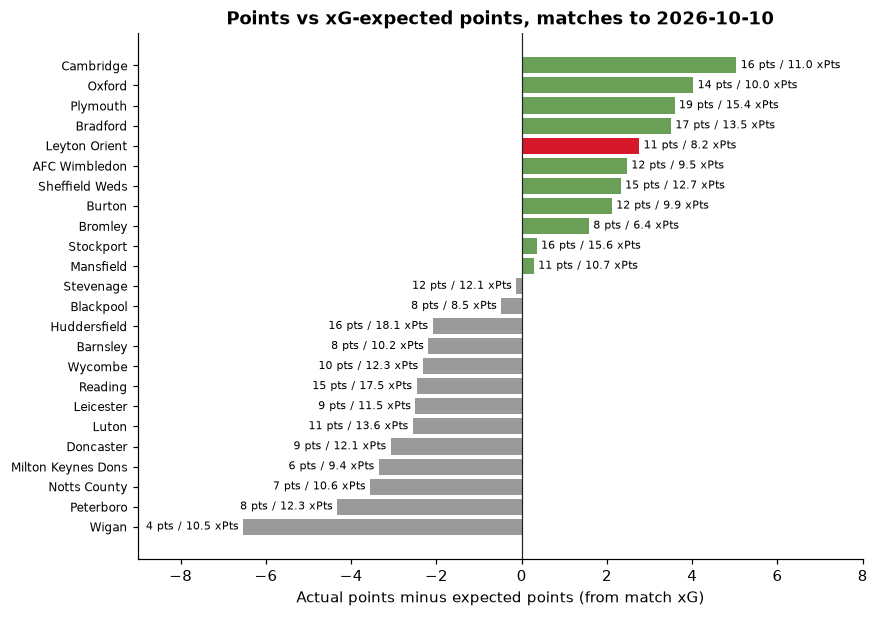

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 6.2))
xx = xp.sort_values("pts_minus_xpts")
cols = [ORIENT if t == TEAM else ("#6a9f58" if v > 0 else "#9a9a9a") for t, v in zip(xx.index, xx.pts_minus_xpts)]
ax.barh(xx.index, xx.pts_minus_xpts, color=cols); ax.axvline(0, color=DARK, lw=0.8)
for i, (t, r) in enumerate(xx.iterrows()):
    ax.text(r.pts_minus_xpts + (0.1 if r.pts_minus_xpts >= 0 else -0.1), i, f"{int(r.pts)} pts / {r.xpts:.1f} xPts",
            va="center", ha="left" if r.pts_minus_xpts >= 0 else "right", fontsize=7)
ax.set_xlabel("Actual points minus expected points (from match xG)"); ax.tick_params(axis="y", labelsize=8)
ax.set_title(f"Points vs xG-expected points, matches to {KEY['xg_last_date']}"); ax.set_xlim(-9, 8)
save(fig, "05_points_vs_xpts.png")

Orient's 11 points from these 9 matches compare with **8.2 expected points from xG (23rd of 24)**.
The betting market, though, priced them at 11.0 expected points before kick-off. That is a reminder that xG over nine games is noisy, and that the market rated Orient's squad as mid-table.

**What has predicted the rest of a League One season?** For every team-season from 2017/18 to 2025/26 I take numbers from the first 9 matches and correlate them with points per game over the remaining matches. I also check how much each measure carries over from one season to the next.

215 team-seasons (167 with closing odds: the average-closing-odds columns start in 2019/20)
136 consecutive team-season pairs


Save rate (1 - GA/SoT against)    0.103
Finishing (goals per SoT)         0.197
Points per game                   0.445
Shot share                        0.489
Shots-on-target share             0.493
Goal difference per game          0.509
Betting-market expected points    0.586
Name: rest_ppg, dtype: float64

Shot share                        0.512
Shots-on-target share             0.473
Finishing (goals per SoT)         0.081
Save rate (1 - GA/SoT against)    0.163
dtype: float64

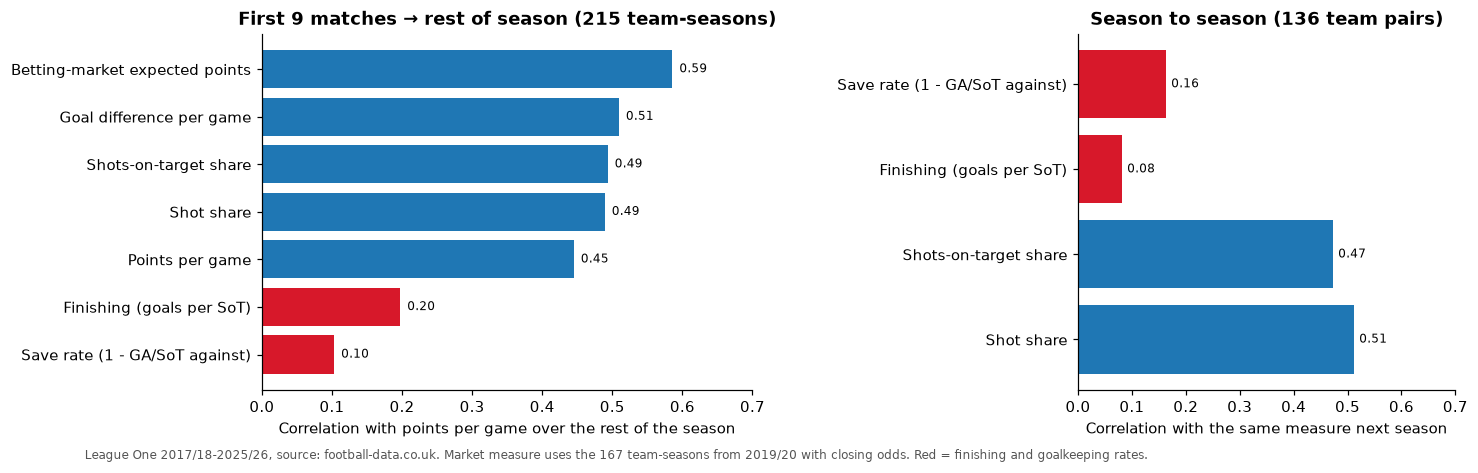

In [16]:
h = tv[(tv.source == "football-data.co.uk") & (tv.season < "2026/27")].copy()
h["n"] = h.groupby(["season", "team"]).cumcount()
rows = []
for (s, tm), g in h.groupby(["season", "team"]):
    a, b = g[g.n < 9], g[g.n >= 9]
    rows.append(dict(season=s, team=tm, rest_ppg=b.pts.mean(), **{
        "Points per game": a.pts.mean(), "Goal difference per game": (a.gf - a.ga).mean(),
        "Shot share": a.sf.sum() / (a.sf.sum() + a.sa.sum()),
        "Shots-on-target share": a.sotf.sum() / (a.sotf.sum() + a.sota.sum()),
        "Finishing (goals per SoT)": a.gf.sum() / a.sotf.sum(),
        "Save rate (1 - GA/SoT against)": 1 - a.ga.sum() / a.sota.sum(),
        "Betting-market expected points": (3 * a.p_win_mkt + a.p_draw_mkt).mean()}))
early = pd.DataFrame(rows).dropna(subset=["rest_ppg"])
pred = early.drop(columns=["season", "team"]).corr()["rest_ppg"].drop("rest_ppg").sort_values()
n_mkt = int(early["Betting-market expected points"].notna().sum())
print(f"{len(early)} team-seasons ({n_mkt} with closing odds: the average-closing-odds columns start in 2019/20)")
KEY["n_team_seasons_early"] = len(early); KEY["n_team_seasons_mkt"] = n_mkt
KEY["early_corr"] = pred.round(2).to_dict()

ts = h.groupby(["season", "team"]).agg(GF=("gf", "sum"), GA=("ga", "sum"), SF=("sotf", "sum"), SA=("sota", "sum"),
                                       sf=("sf", "sum"), sa=("sa", "sum")).reset_index()
ts["Finishing (goals per SoT)"] = ts.GF / ts.SF; ts["Save rate (1 - GA/SoT against)"] = 1 - ts.GA / ts.SA
ts["Shots-on-target share"] = ts.SF / (ts.SF + ts.SA); ts["Shot share"] = ts.sf / (ts.sf + ts.sa)
seasons = sorted(ts.season.unique()); ts["next"] = ts.season.map(dict(zip(seasons[:-1], seasons[1:])))
j = ts.merge(ts, left_on=["next", "team"], right_on=["season", "team"], suffixes=("", "_n"))
persist = pd.Series({k: j[k].corr(j[k + "_n"]) for k in ["Shot share", "Shots-on-target share", "Finishing (goals per SoT)", "Save rate (1 - GA/SoT against)"]})
KEY["persist"] = persist.round(2).to_dict(); KEY["n_persist"] = len(j)
print(f"{len(j)} consecutive team-season pairs"); display(pred.round(3)); display(persist.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.75})
ax = axes[0]
cols = [ORIENT if k in ("Finishing (goals per SoT)", "Save rate (1 - GA/SoT against)") else OPP for k in pred.index]
ax.barh(pred.index, pred.values, color=cols)
for i, v in enumerate(pred.values): ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlim(0, 0.7); ax.set_xlabel("Correlation with points per game over the rest of the season")
ax.set_title(f"First 9 matches → rest of season ({len(early)} team-seasons)")
ax = axes[1]
cols = [ORIENT if "Finishing" in k or "Save" in k else OPP for k in persist.index]
ax.barh(persist.index, persist.values, color=cols)
for i, v in enumerate(persist.values): ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlim(0, 0.7); ax.set_xlabel("Correlation with the same measure next season")
ax.set_title(f"Season to season ({len(j)} team pairs)")
fig.text(0.01, -0.04, f"League One 2017/18-2025/26, source: football-data.co.uk. Market measure uses the {n_mkt} team-seasons from 2019/20 with closing odds. Red = finishing and goalkeeping rates.", fontsize=8, color="#555")
save(fig, "06_what_predicts.png")

Shot and shot-on-target shares carry real signal (about 0.49-0.50 correlation with future points, and 0.47-0.51 year to year).
Finishing and save rates are mostly noise over nine games, and barely carry over between seasons (0.08 and 0.16).
The betting market's view is the best single early indicator (computed for the seasons with closing odds in the files).

Orient's 2026/27 profile is the risky kind: a shots-on-target share of 45% (below the 50% average) propped up by finishing and save rates above the play-off average (next section).

## 5. Three seasons of context: Orient vs League One's top six

In [17]:
full = tv[(tv.source == "football-data.co.uk")].copy()
full["xpm"] = 3 * full.p_win_mkt + full.p_draw_mkt
S = full.groupby(["season", "team"]).agg(P=("pts", "size"), ppg=("pts", "mean"), sf=("sf", "mean"), sa=("sa", "mean"),
                                        sotf=("sotf", "mean"), sota=("sota", "mean"), cf=("cf", "mean"), ca=("ca", "mean"),
                                        GF=("gf", "sum"), GA=("ga", "sum"), SF=("sotf", "sum"), SA=("sota", "sum"), xpm=("xpm", "mean")).reset_index()
S["conv"] = S.GF / S.SF; S["save"] = 1 - S.GA / S.SA; S["sot_share"] = S.SF / (S.SF + S.SA)
S["rank"] = S.groupby("season").ppg.rank(ascending=False, method="first")
hist = S[S.season < "2026/27"]
cols = ["ppg", "sf", "sa", "sotf", "sota", "sot_share", "conv", "save", "cf", "ca", "xpm"]
top6_avg = hist[hist["rank"] <= 6][cols].mean().rename("Top-six average 2017/18-2025/26")
lg_avg = hist[cols].mean().rename("League average 2017/18-2025/26")
orient_hist = S[S.team == TEAM].set_index("season")[["P"] + cols]
pos = {s: int(league_table(allE2[allE2.season == s]).loc[TEAM, "Pos"]) for s in orient_hist.index}
orient_hist.insert(0, "Pos", pd.Series(pos))
prof = pd.concat([orient_hist, top6_avg.to_frame().T, lg_avg.to_frame().T])
prof.columns = ["Pos", "P", "Pts/game", "Shots for", "Shots against", "SoT for", "SoT against", "SoT share",
                "Goals per SoT", "Save rate", "Corners for", "Corners against", "Market xPts/game"]
KEY["profile"] = prof.round(3).astype(object).where(prof.notna(), None).to_dict(orient="index")
prof.round(3)

,Pos,P,Pts/game,Shots for,Shots against,SoT for,SoT against,SoT share,Goals per SoT,Save rate,Corners for,Corners against,Market xPts/game
2023/24,12.0,46.0,1.413,11.870,10.543,4.043,3.913,0.508,0.285,0.694,5.565,4.826,1.348
2024/25,6.0,46.0,1.696,11.261,10.543,4.217,3.717,0.532,0.371,0.719,5.217,4.217,1.452
2025/26,20.0,46.0,1.130,11.152,12.109,3.696,4.543,0.449,0.347,0.660,4.761,4.870,1.301
2026/27,9.0,9.0,1.222,10.333,15.222,3.667,4.556,0.446,0.394,0.732,3.667,6.778,1.221
Top-six average 2017/18-2025/26,NaN,NaN,1.854,13.078,10.205,4.691,3.406,0.580,0.349,0.705,5.631,4.489,1.646
League average 2017/18-2025/26,NaN,NaN,1.372,11.810,11.812,4.065,4.065,0.500,0.320,0.680,5.134,5.135,1.366


*2026/27 rows use the 9 matches with stats (to 10 Oct). Final positions are computed from results and ignore any points deductions. Market expected points use average closing odds, available from 2019/20.*

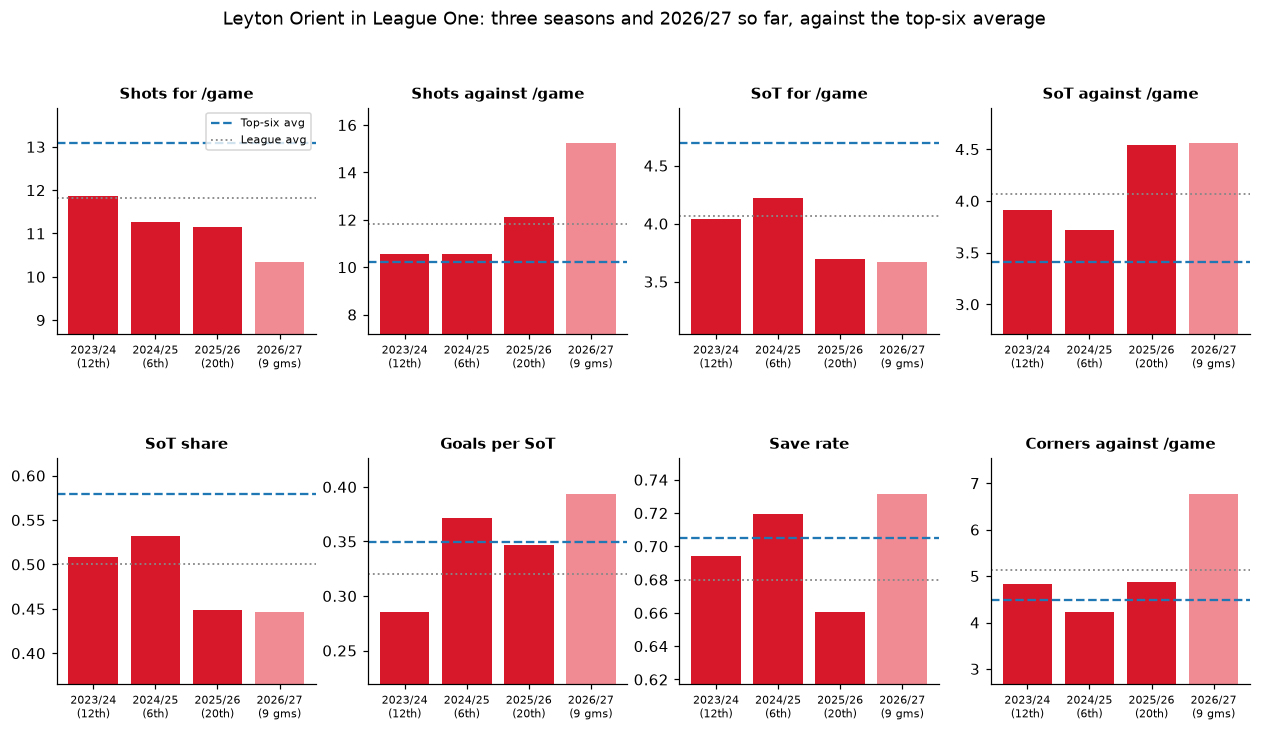

In [18]:
metrics = [("sf", "Shots for /game"), ("sa", "Shots against /game"), ("sotf", "SoT for /game"), ("sota", "SoT against /game"),
           ("sot_share", "SoT share"), ("conv", "Goals per SoT"), ("save", "Save rate"), ("ca", "Corners against /game")]
seasons_o = list(orient_hist.index)
fig, axes = plt.subplots(2, 4, figsize=(14, 6.8), gridspec_kw={"hspace": 0.55})
for ax, (k, lab) in zip(axes.ravel(), metrics):
    vals = orient_hist[k].values
    bars = ax.bar(range(len(vals)), vals, color=[ORIENT if s != "2026/27" else "#f08a93" for s in seasons_o])
    ax.axhline(top6_avg[k], color=OPP, ls="--", lw=1.5, label="Top-six avg"); ax.axhline(lg_avg[k], color="#888", ls=":", lw=1.2, label="League avg")
    ax.set_xticks(range(len(vals))); ax.set_xticklabels([f"{s}\n({orient_hist.loc[s, 'Pos']}th)" if s != "2026/27" else f"{s}\n(9 gms)" for s in seasons_o], fontsize=7)
    ax.set_title(lab, fontsize=10)
    lo = min(vals.min(), top6_avg[k], lg_avg[k]); hi = max(vals.max(), top6_avg[k], lg_avg[k]); ax.set_ylim(lo - (hi - lo) * 0.6, hi + (hi - lo) * 0.3)
axes[0, 0].legend(fontsize=7)
fig.suptitle("Leyton Orient in League One: three seasons and 2026/27 so far, against the top-six average", y=1.01)
save(fig, "07_orient_multiseason_profile.png")

* **2024/25 (6th, 78 points)** was built on a positive shots-on-target share (53%) and good finishing (0.37 goals per SoT, above the top-six average of 0.35), but the shot numbers were never at top-six level (11.3 for, 10.5 against).
* **2025/26 (20th, 52 points)**: SoT share fell to 45%, SoT conceded rose to 4.5 a game, and the save rate dropped to 0.66.
* **2026/27 so far:** SoT share is still 45%, and shots conceded have risen to 15.2 a game (top-six average 10.2). Points have held up because finishing (0.39) and saves (0.73) are both above top-six levels, and the persistence numbers above say these rates are unlikely to last.

## 6. What would most improve results?

Across 215 League One team-seasons (2017/18 to 2025/26), points per game are regressed on shots on target for and against per game.

In [19]:
r1 = smf.ols("ppg ~ sotf + sota", hist).fit()
r2 = smf.ols("ppg ~ sotf + sota + conv + save", hist).fit()
print(r1.summary().tables[1]); print("R² =", round(r1.rsquared, 3), "| with finishing and save rate: R² =", round(r2.rsquared, 3))
KEY["reg"] = {"n": int(r1.nobs), "r2": round(r1.rsquared, 3), "b_sotf": round(r1.params.sotf, 3), "b_sota": round(r1.params.sota, 3),
              "ci_sotf": [round(v, 3) for v in r1.conf_int().loc["sotf"]], "ci_sota": [round(v, 3) for v in r1.conf_int().loc["sota"]],
              "r2_full": round(r2.rsquared, 3)}

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.4538      0.161      9.041      0.000       1.137       1.771
sotf           0.2484      0.024     10.437      0.000       0.202       0.295
sota          -0.2685      0.023    -11.820      0.000      -0.313      -0.224
R² = 0.674 | with finishing and save rate: R² = 0.913


In [20]:
cur_o = S[(S.team == TEAM) & (S.season == "2026/27")].iloc[0]
lev = pd.DataFrame({
    "Orient 2026/27": [cur_o.sotf, cur_o.sota],
    "Top-six average": [top6_avg.sotf, top6_avg.sota],
}, index=["SoT for /game", "SoT against /game"])
lev["Gap"] = lev["Top-six average"] - lev["Orient 2026/27"]
lev["Pts/game from closing gap"] = [lev.Gap.iloc[0] * r1.params.sotf, lev.Gap.iloc[1] * r1.params.sota]
lev["Pts over a 46-game season"] = lev["Pts/game from closing gap"] * 46
remaining = 46 - KEY["orient_p"]
lev[f"Pts over remaining {remaining} games"] = lev["Pts/game from closing gap"] * remaining
pred_now = r1.predict(pd.DataFrame({"sotf": [cur_o.sotf], "sota": [cur_o.sota]}))[0]
KEY["lever"] = {"sotf": round(cur_o.sotf, 2), "sota": round(cur_o.sota, 2), "top6_sotf": round(top6_avg.sotf, 2), "top6_sota": round(top6_avg.sota, 2),
                "pts46_sotf": round(lev.iloc[0, 4], 1), "pts46_sota": round(lev.iloc[1, 4], 1),
                "per1_sot_46": round(r1.params.sotf * 46, 1), "per1_sota_46": round(-r1.params.sota * 46, 1),
                "ppg_pred_now": round(pred_now, 2), "pts46_pred_now": round(pred_now * 46, 1)}
lev.round(2)

,Orient 2026/27,Top-six average,Gap,Pts/game from closing gap,Pts over a 46-game season,Pts over remaining 36 games
SoT for /game,3.67,4.69,1.02,0.25,11.71,9.16
SoT against /game,4.56,3.41,-1.15,0.31,14.20,11.11


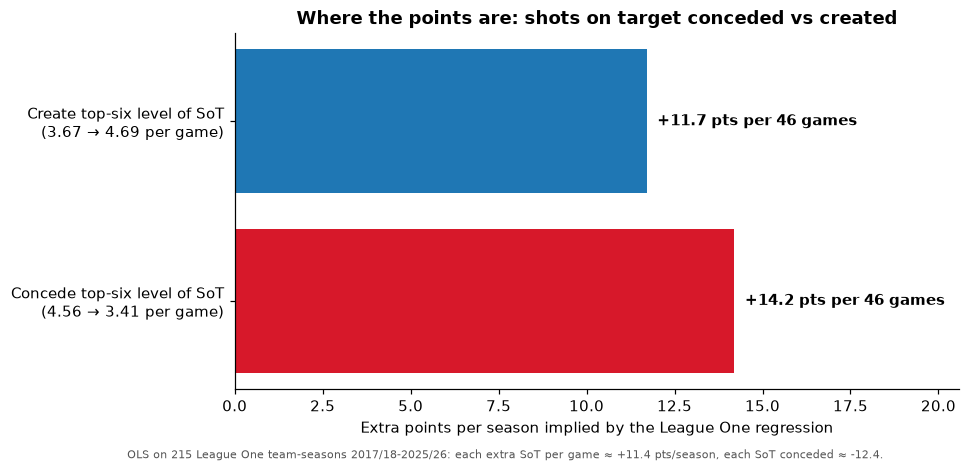

In [21]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
labels = ["Concede top-six level of SoT\n(4.56 → 3.41 per game)", "Create top-six level of SoT\n(3.67 → 4.69 per game)"]
vals = [lev.iloc[1, 4], lev.iloc[0, 4]]
ax.barh(labels, vals, color=[ORIENT, OPP])
for i, v in enumerate(vals): ax.text(v + 0.3, i, f"+{v:.1f} pts per 46 games", va="center", fontweight="bold")
ax.set_xlim(0, max(vals) * 1.45); ax.set_xlabel("Extra points per season implied by the League One regression")
ax.set_title("Where the points are: shots on target conceded vs created")
fig.text(0.01, -0.04, f"OLS on {int(r1.nobs)} League One team-seasons 2017/18-2025/26: each extra SoT per game ≈ +{r1.params.sotf*46:.1f} pts/season, each SoT conceded ≈ {r1.params.sota*46:.1f}.",
        fontsize=7.5, color="#555")
save(fig, "08_improvement_levers.png")

On this season's underlying numbers (3.7 SoT for, 4.6 against), the regression expects about **1.14 points per game, or 52-53 points over 46 games**, which is lower-mid-table (Orient's 52 points finished 20th in 2025/26).
The single biggest lever is the defensive volume: getting shots on target conceded down to the top-six average would be worth about **+14 points a season**, compared with about +12 for matching top-six creation.
The two levers are related in practice: Orient concede territory (6.8 corners against a game, 15.2 shots against), so the defensive gain probably comes from keeping the ball further up the pitch, not only from defending the box better.

**Game state.** Points per game by half-time situation, Orient vs the League One average:

In [22]:
gs = tv[tv.source == "football-data.co.uk"].copy(); gs["ht"] = np.sign(gs.ht_gf - gs.ht_ga).map({-1: "Behind at HT", 0: "Level at HT", 1: "Ahead at HT"})
lgs = gs[gs.season < "2026/27"].groupby("ht").pts.mean().rename("League avg 2017/18-2025/26")
ogs = gs[gs.team == TEAM].pivot_table(index="ht", columns="season", values="pts", aggfunc="mean")
ogn = gs[gs.team == TEAM].pivot_table(index="ht", columns="season", values="pts", aggfunc="size")
display(pd.concat([ogs.round(2), lgs.round(2)], axis=1)); display(ogn)
KEY["gamestate"] = {"level_ppg": ogs.loc["Level at HT"].round(2).to_dict(), "level_n": ogn.loc["Level at HT"].to_dict(),
                    "league_level_ppg": round(lgs["Level at HT"], 2), "ahead_ppg": ogs.loc["Ahead at HT"].round(2).to_dict()}

,2023/24,2024/25,2025/26,2026/27,League avg 2017/18-2025/26
ht,,,,,
Ahead at HT,2.08,2.67,2.50,3.0,2.41
Behind at HT,0.36,0.70,0.54,0.0,0.40
Level at HT,1.55,1.28,0.87,1.0,1.32


season,2023/24,2024/25,2025/26,2026/27
ht,,,,
Ahead at HT,13,18,10,2
Behind at HT,11,10,13,2
Level at HT,22,18,23,5


In 2025/26 Orient took only 0.87 points per game from matches level at half-time (23 matches), against a league average of 1.32, a gap of roughly 10 points over the season.
In 2026/27 they have won both football-data matches they led at half-time (Wigan and Bromley), and the Blackpool game (1-0 at half-time) makes it three from three. They have taken 1.00 point per game from the five matches level at the break.

## 7. Match model: Dixon-Coles ratings and season projection

A time-weighted Dixon-Coles model (`src/model.py`) gives each team an attack and a defence rating from **scores alone**, with recent matches weighted more (half-life 240 days) and a small ridge penalty.
It is fitted on Championship, League One and League Two matches together from 2022/23, so promoted and relegated teams (for example Leicester, or clubs up from League Two) carry their ratings across divisions.

**Validation.** The half-life and penalty were chosen on a walk-forward test over League One 2024/25 (refit every 14 days on past matches only). The table below is the untouched **2025/26** season, compared with the bookmakers' closing odds (overround removed) and with always predicting the average home/draw/away rates.

In [23]:
allm = pd.concat([load_matches(d) for d in ["E1", "E2", "E3"]], ignore_index=True)
allm = allm[allm.Date >= "2022-07-01"].sort_values("Date", kind="stable").reset_index(drop=True)
HL, RIDGE = 240, 0.25
tgt = allm[(allm.Div == "E2") & (allm.season == "2025/26")]
wf = walk_forward(allm, tgt, HL, RIDGE, step_days=14)
o = wf.FTR.map({"H": 0, "D": 1, "A": 2}).to_numpy()
P_model = wf[["pH", "pD", "pA"]].to_numpy()
inv = 1 / wf[["AvgCH", "AvgCD", "AvgCA"]]; P_mkt = inv.div(inv.sum(axis=1), axis=0).to_numpy()
prev = allm[(allm.Div == "E2") & (allm.season == "2024/25")].FTR.value_counts(normalize=True).reindex(["H", "D", "A"]).to_numpy()
P_base = np.tile(prev, (len(o), 1))
def scores(P):
    return {"log loss": -np.log(P[np.arange(len(P)), o]).mean(), "RPS": rps(P, o).mean(),
            "accuracy": (P.argmax(1) == o).mean()}
val = pd.DataFrame({"Base rates (2024/25 H/D/A)": scores(P_base), "Dixon-Coles (scores only)": scores(P_model),
                    "Betting market (closing avg)": scores(P_mkt)}).T
KEY["val"] = {k: {kk: round(vv, 4) for kk, vv in v.items()} for k, v in val.to_dict(orient="index").items()}; KEY["val_n"] = len(o)
print(f"League One 2025/26, {len(o)} matches, walk-forward"); val.round(4)

League One 2025/26, 552 matches, walk-forward


,log loss,RPS,accuracy
Base rates (2024/25 H/D/A),1.0670,0.2280,0.4601
Dixon-Coles (scores only),1.0405,0.2184,0.4855
Betting market (closing avg),1.0153,0.2097,0.5091


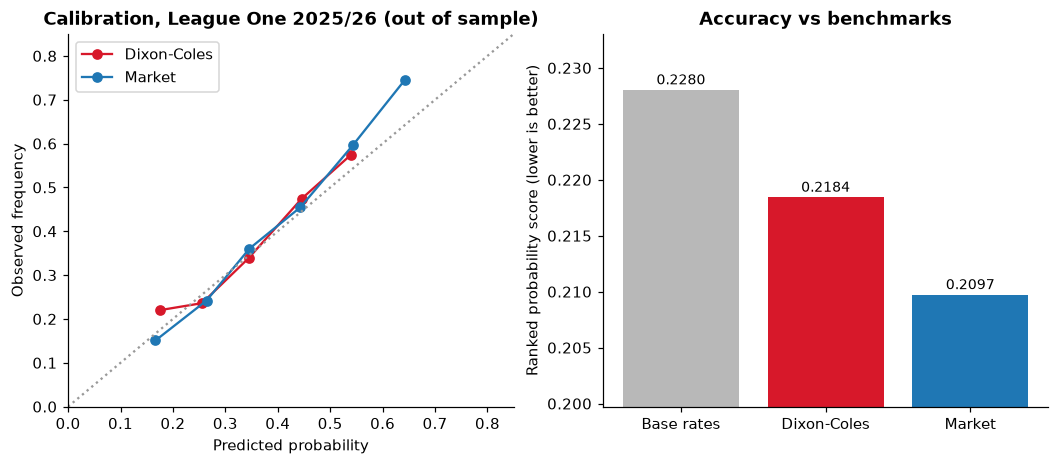

In [24]:
bins = np.linspace(0, 1, 11)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
ax = axes[0]
for P, lab, col in [(P_model, "Dixon-Coles", ORIENT), (P_mkt, "Market", OPP)]:
    pr = P.ravel(); hit = np.eye(3)[o].ravel(); b = np.digitize(pr, bins) - 1
    cal = pd.DataFrame({"b": b, "p": pr, "y": hit}).groupby("b").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    cal = cal[cal.n >= 20]; ax.plot(cal.p, cal.y, "o-", color=col, label=lab)
ax.plot([0, 1], [0, 1], color="#999", ls=":"); ax.set_xlim(0, 0.85); ax.set_ylim(0, 0.85)
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed frequency"); ax.legend(); ax.set_title("Calibration, League One 2025/26 (out of sample)")
ax = axes[1]
vv = val["RPS"]; ax.bar(range(3), vv, color=[GREY, ORIENT, OPP]); ax.set_xticks(range(3)); ax.set_xticklabels(["Base rates", "Dixon-Coles", "Market"])
ax.set_ylim(vv.min() - 0.01, vv.max() + 0.005); ax.set_ylabel("Ranked probability score (lower is better)")
for i, v in enumerate(vv): ax.text(i, v + 0.0005, f"{v:.4f}", ha="center", fontsize=9)
ax.set_title("Accuracy vs benchmarks")
save(fig, "09_model_validation.png")

The model is well calibrated and closes about half the gap between naive base rates and the closing market, which also prices in team news, injuries and transfers that scores alone cannot see.
That makes it a reasonable, transparent baseline for projections, not a betting tool.

**Current ratings (fitted on all matches to 17 Oct 2026)**, expressed as expected goals for and against an average team across the three divisions (Championship, League One, League Two) at a neutral venue.

In [25]:
ref = pd.Timestamp("2026-10-18")
dc = DixonColes(HL, RIDGE).fit(allm, ref)
teams27 = sorted(set(cur.HomeTeam) | set(cur.AwayTeam))
rt = dc.ratings(teams27); rt["rank"] = range(1, len(rt) + 1)
KEY["dc_rank"] = int(rt.loc[TEAM, "rank"]); KEY["dc_orient"] = [round(rt.loc[TEAM, "xg_for"], 2), round(rt.loc[TEAM, "xg_against"], 2)]
KEY["dc_home_adv"] = round(float(np.exp(dc.home)), 3); KEY["dc_rho"] = round(float(dc.rho), 3)
rt.round(3)

,attack,defence,xg_for,xg_against,net,rank
Oxford,0.124,0.235,1.462,1.020,0.441,1
Stockport,0.205,0.089,1.585,1.181,0.404,2
Leicester,0.170,0.071,1.530,1.203,0.328,3
Plymouth,0.207,-0.030,1.587,1.330,0.257,4
Huddersfield,0.150,0.008,1.499,1.281,0.218,5
Luton,0.172,-0.026,1.532,1.325,0.208,6
Reading,0.171,-0.028,1.532,1.327,0.205,7
Sheffield Weds,0.049,0.031,1.355,1.251,0.104,8
Bradford,-0.155,0.242,1.105,1.014,0.092,9
Wycombe,0.111,-0.088,1.443,1.409,0.034,10


In [26]:
sim, posm = simulate_season(dc, cur, teams27, n_sims=10000, seed=7)
oi = teams27.index(TEAM)
KEY["sim"] = {k: round(float(v), 3) for k, v in sim.loc[TEAM].items()}
KEY["sim_median_pos"] = int(np.median(posm[:, oi])); KEY["sim_pos_p10_p90"] = [int(np.percentile(posm[:, oi], 10)), int(np.percentile(posm[:, oi], 90))]
sim.round(3)

,mean_pts,p10_pts,p90_pts,mean_pos,p_top2,p_top6,p_bottom4
team,,,,,,,
Oxford,81.144,71.0,91.0,3.352,0.516,0.866,0.000
Stockport,79.455,70.0,89.0,3.932,0.425,0.820,0.000
Huddersfield,75.407,65.0,85.0,5.604,0.230,0.651,0.000
Plymouth,74.256,64.0,84.0,6.169,0.178,0.587,0.000
Bradford,72.866,63.0,83.0,6.912,0.130,0.505,0.002
Leicester,72.295,62.0,82.0,7.210,0.123,0.485,0.002
Sheffield Weds,72.150,62.0,82.0,7.135,0.126,0.482,0.001
Reading,70.469,61.0,80.0,7.926,0.094,0.414,0.003
Luton,69.262,59.0,79.0,8.697,0.067,0.346,0.008


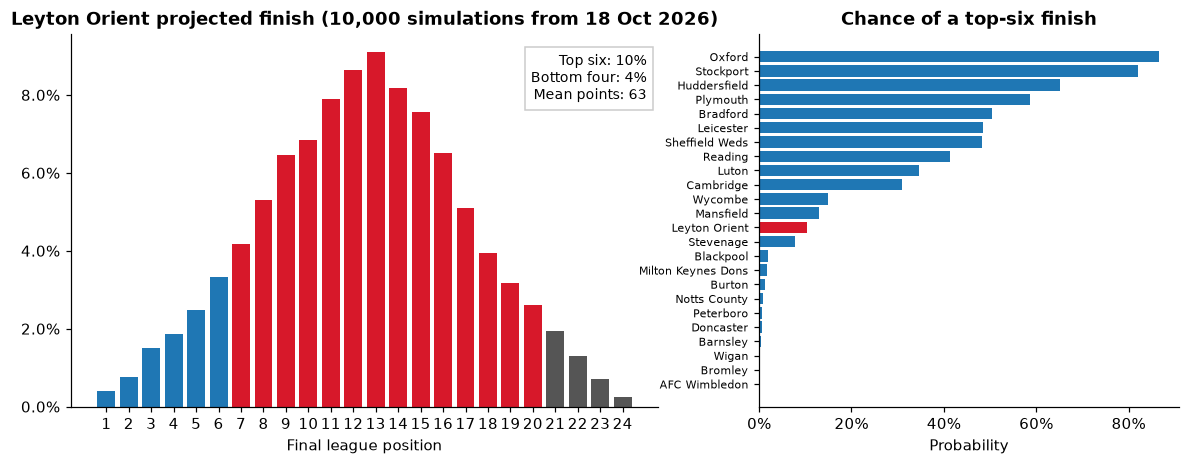

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
dist = pd.Series(posm[:, oi]).value_counts(normalize=True).reindex(range(1, 25), fill_value=0)
ax.bar(dist.index, dist.values, color=[OPP if p <= 6 else ("#555" if p >= 21 else ORIENT) for p in dist.index])
ax.set_xticks(range(1, 25)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlabel("Final league position")
ax.set_title(f"Leyton Orient projected finish (10,000 simulations from 18 Oct 2026)")
ax.text(0.98, 0.95, f"Top six: {sim.loc[TEAM,'p_top6']:.0%}\nBottom four: {sim.loc[TEAM,'p_bottom4']:.0%}\nMean points: {sim.loc[TEAM,'mean_pts']:.0f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=9, bbox=dict(facecolor="white", edgecolor="#ccc"))
ax = axes[1]
sp = sim.sort_values("mean_pts")
ax.barh(sp.index, sp.p_top6, color=[ORIENT if t == TEAM else OPP for t in sp.index]); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.tick_params(axis="y", labelsize=7.5); ax.set_title("Chance of a top-six finish"); ax.set_xlabel("Probability")
save(fig, "10_season_projection.png")

Because the model reads goals, not xG, it rates Orient **14th**: their goal difference (+4) is better than their xG difference.
If the xG picture is right, the projection below is, if anything, generous to Orient.

### Next three fixtures (model probabilities, from the ratings above)

In [28]:
nxt = [("2026-10-21", "Reading", TEAM), ("2026-10-24", "Burton", TEAM), ("2026-10-31", TEAM, "Cambridge")]
rows = []
for dte, hm, aw in nxt:
    ph, pdr, pa = dc.predict(hm, aw); lh, la = dc._lams(pd.Index([hm]), pd.Index([aw]))
    win, loss = (ph, pa) if hm == TEAM else (pa, ph)
    rows.append({"date": dte, "fixture": f"{hm} v {aw}", "Orient win": win, "draw": pdr, "Orient loss": loss,
                 "model xG home": lh[0], "model xG away": la[0]})
fx = pd.DataFrame(rows); KEY["next"] = fx.round(3).to_dict(orient="records"); fx.round(2)

,date,fixture,Orient win,draw,Orient loss,model xG home,model xG away
0,2026-10-21,Reading v Leyton Orient,0.26,0.24,0.50,1.75,1.20
1,2026-10-24,Burton v Leyton Orient,0.36,0.27,0.37,1.29,1.29
2,2026-10-31,Leyton Orient v Cambridge,0.40,0.28,0.32,1.26,1.09


In [29]:
opp_prof = lg.loc[["Reading", "Burton", "Cambridge"], ["P", "xgf", "xga", "sf", "sa", "xg_per_shot", "cf", "ca", "xgd_rank"]]
KEY["opp_prof"] = opp_prof.round(3).to_dict(orient="index"); opp_prof.round(2)

,P,xgf,xga,sf,sa,xg_per_shot,cf,ca,xgd_rank
team,,,,,,,,,
Reading,9,2.05,0.97,16.56,11.00,0.12,5.67,3.78,2
Burton,10,0.83,1.51,10.10,13.10,0.08,3.80,5.40,22
Cambridge,9,1.13,1.42,13.67,11.89,0.08,7.00,4.33,18


**Reading (away, Wed 21 Oct)** are the league's second-best side by xG difference (2.05 for, 0.97 against per game) and have scored 22 league goals, the most in the division.
On the evidence of Bradford and Blackpool, expect Orient to have less of the ball; the key numbers to watch are shots on target conceded and corners conceded.

In [30]:
json.dump(KEY, open(RES / "key_numbers.json", "w"), indent=2, default=lambda x: x.item() if hasattr(x, "item") else str(x))
table.to_csv(RES / "league_one_table_2026-10-17.csv"); lg.round(4).to_csv(RES / "league_one_xg_2026-10-10.csv")
xp.round(3).to_csv(RES / "points_vs_xpts_2026-10-10.csv"); prof.round(4).to_csv(RES / "orient_season_profiles.csv")
sim.round(4).to_csv(RES / "season_projection_2026-10-18.csv"); rt.round(4).to_csv(RES / "dixon_coles_ratings_2026-10-18.csv")
val.round(4).to_csv(RES / "model_validation_2025_26.csv")
print("saved", sorted(p.name for p in RES.iterdir()))

saved ['dixon_coles_ratings_2026-10-18.csv', 'key_numbers.json', 'league_one_table_2026-10-17.csv', 'league_one_xg_2026-10-10.csv', 'model_validation_2025_26.csv', 'orient_season_profiles.csv', 'points_vs_xpts_2026-10-10.csv', 'season_projection_2026-10-18.csv']
